# NB03: Diffusion MRI and Tractography

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB03_Diffusion_MRI_and_Tractography.ipynb)


## Learning Objectives
- Understand diffusion tensor imaging (DTI) fundamentally
- Load diffusion-weighted images (DWI), b-values, and b-vectors
- Compute diffusion tensor properties: FA, MD, AD, RD
- Interpret DTI metrics in the context of white matter and tumor
- Visualize fiber tractography and explain the tractography concept
- Apply mathematical frameworks (eigenvalue decomposition, tensor mathematics)

## Overview
Diffusion MRI measures water diffusion anisotropy, revealing white matter microstructure. This notebook teaches the mathematical foundations of DTI and practical computation of clinically relevant metrics.

In [28]:
# Setup paths and imports
import os
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
from scipy import ndimage

# Try to import dipy for advanced analysis
try:
    from dipy.io.image import load_nifti
    from dipy.io.gradients import read_bvals_bvecs
    from dipy.core.gradients import gradient_table
    from dipy.reconst.dti import TensorModel
    DIPY_AVAILABLE = True
except ImportError:
    print('DIPY not available - some analyses will be skipped')
    DIPY_AVAILABLE = False

# Environment setup
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             '/content/glioma-brain-digital-twin'],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r /content/glioma-brain-digital-twin/environment/requirements-colab.txt
    if not (REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'sub-PAT16').exists():
        !python /content/glioma-brain-digital-twin/data/download_data.py
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent
DATA_ROOT = REPO_ROOT / 'data' / 'BIDS_preop_postop'

print(f'Data root: {DATA_ROOT}')
print(f'DIPY available: {DIPY_AVAILABLE}')
%matplotlib inline

Data root: <REPO_ROOT>/data/BIDS_preop_postop
DIPY available: True


### 1. Diffusion Tensor Theory for Applied Mathematicians

In [29]:
theory = '''DIFFUSION TENSOR IMAGING (DTI) - MATHEMATICAL FOUNDATIONS
=============================================================

PHYSICAL BASIS:
Water molecules in tissue move via Brownian motion. The rate and direction
of diffusion depends on tissue microstructure.

THE DIFFUSION TENSOR (D):
Water diffusion in anisotropic media (e.g., along axons) follows:
  dP/dt = D * ∇^2 P

where P is the probability density and D is a 3x3 symmetric tensor:

       [ Dxx  Dxy  Dxz ]
  D =  [ Dxy  Dyy  Dyz ]
       [ Dxz  Dyz  Dzz ]

EIGENVALUE DECOMPOSITION:
D = V * Lambda * V^T

where:
  Lambda = diag(λ1, λ2, λ3)  are eigenvalues (diffusivities along principal axes)
  V are corresponding eigenvectors (principal diffusion directions)

By convention: λ1 ≥ λ2 ≥ λ3

KEY DTI METRICS:

1. MEAN DIFFUSIVITY (MD):
   MD = (λ1 + λ2 + λ3) / 3
   
   Interpretation:
   - Average water diffusion in all directions
   - High MD = edema, necrosis
   - Low MD = high cellularity (tumor)

2. FRACTIONAL ANISOTROPY (FA):
   FA = sqrt(3/2) * sqrt((λ1-MD)^2 + (λ2-MD)^2 + (λ3-MD)^2) / sqrt(λ1^2 + λ2^2 + λ3^2)
   
   Range: [0, 1]
   
   Interpretation:
   - Measures degree of directional preference
   - High FA = intact white matter fiber bundles
   - Low FA = crossing fibers, demyelination, tumor infiltration

3. AXIAL DIFFUSIVITY (AD):
   AD = λ1
   
   Interpretation:
   - Diffusion along fiber axis
   - Reflects axonal integrity

4. RADIAL DIFFUSIVITY (RD):
   RD = (λ2 + λ3) / 2
   
   Interpretation:
   - Diffusion perpendicular to fibers
   - Sensitive to myelin damage

CLINICAL RELEVANCE FOR GLIOMAS:
- Tumor cores: Low FA, High MD (disrupted structure)
- Peritumoral zone: Intermediate FA (edema + infiltration)
- White matter tracts: High FA baseline
- Surgical planning: Identify eloquent tracts via tractography
'''
print(theory)

DIFFUSION TENSOR IMAGING (DTI) - MATHEMATICAL FOUNDATIONS

PHYSICAL BASIS:
Water molecules in tissue move via Brownian motion. The rate and direction
of diffusion depends on tissue microstructure.

THE DIFFUSION TENSOR (D):
Water diffusion in anisotropic media (e.g., along axons) follows:
  dP/dt = D * ∇^2 P

where P is the probability density and D is a 3x3 symmetric tensor:

       [ Dxx  Dxy  Dxz ]
  D =  [ Dxy  Dyy  Dyz ]
       [ Dxz  Dyz  Dzz ]

EIGENVALUE DECOMPOSITION:
D = V * Lambda * V^T

where:
  Lambda = diag(λ1, λ2, λ3)  are eigenvalues (diffusivities along principal axes)
  V are corresponding eigenvectors (principal diffusion directions)

By convention: λ1 ≥ λ2 ≥ λ3

KEY DTI METRICS:

1. MEAN DIFFUSIVITY (MD):
   MD = (λ1 + λ2 + λ3) / 3

   Interpretation:
   - Average water diffusion in all directions
   - High MD = edema, necrosis
   - Low MD = high cellularity (tumor)

2. FRACTIONAL ANISOTROPY (FA):
   FA = sqrt(3/2) * sqrt((λ1-MD)^2 + (λ2-MD)^2 + (λ3-MD)^2) / sqrt(λ1

### 2. Load DWI Data and b-values/b-vectors

In [30]:
# Find DWI files -- prefer the pre-op AP (full multi-shell) acquisition
dwi_files = sorted(DATA_ROOT.glob('sub-*/ses-*/dwi/*dwi.nii.gz'))
print(f'Found {len(dwi_files)} DWI files')

if dwi_files:
    ap_preop = [f for f in dwi_files if 'preop' in f.name and 'AP' in f.name]
    dwi_path = ap_preop[0] if ap_preop else dwi_files[0]
    print(f'\nLoading: {dwi_path.name}')
    
    # Load NIfTI
    dwi_data = nib.load(str(dwi_path)).get_fdata()
    print(f'DWI shape: {dwi_data.shape}')
    print(f'Data range: [{dwi_data.min():.0f}, {dwi_data.max():.0f}]')
    
    # Load b-values and b-vectors
    bval_path = str(dwi_path).replace('dwi.nii.gz', 'dwi.bval')
    bvec_path = str(dwi_path).replace('dwi.nii.gz', 'dwi.bvec')
    
    if os.path.exists(bval_path) and os.path.exists(bvec_path):
        bvals = np.loadtxt(bval_path)
        bvecs = np.loadtxt(bvec_path)
        
        print(f'\nB-values shape: {bvals.shape}')
        print(f'B-vectors shape: {bvecs.shape}')
        print(f'\nUnique b-values: {np.unique(bvals)}')
        print(f'b=0 volumes (B0): {(bvals == 0).sum()}')
        print(f'DWI volumes: {(bvals > 0).sum()}')
    else:
        print(f'\nWarning: b-value/b-vector files not found')
        print(f'Expected: {bval_path}')
        print(f'Expected: {bvec_path}')
        bvals = None
        bvecs = None
else:
    print('No DWI files found')
    dwi_data = None
    bvals = None
    bvecs = None

Found 4 DWI files

Loading: sub-PAT16_ses-preop_acq-AP_dwi.nii.gz
DWI shape: (96, 96, 60, 102)
Data range: [0, 2582]

B-values shape: (102,)
B-vectors shape: (3, 102)

Unique b-values: [   0.  700. 1200. 2800.]
b=0 volumes (B0): 6
DWI volumes: 96


### 3. Visualize DWI Volumes

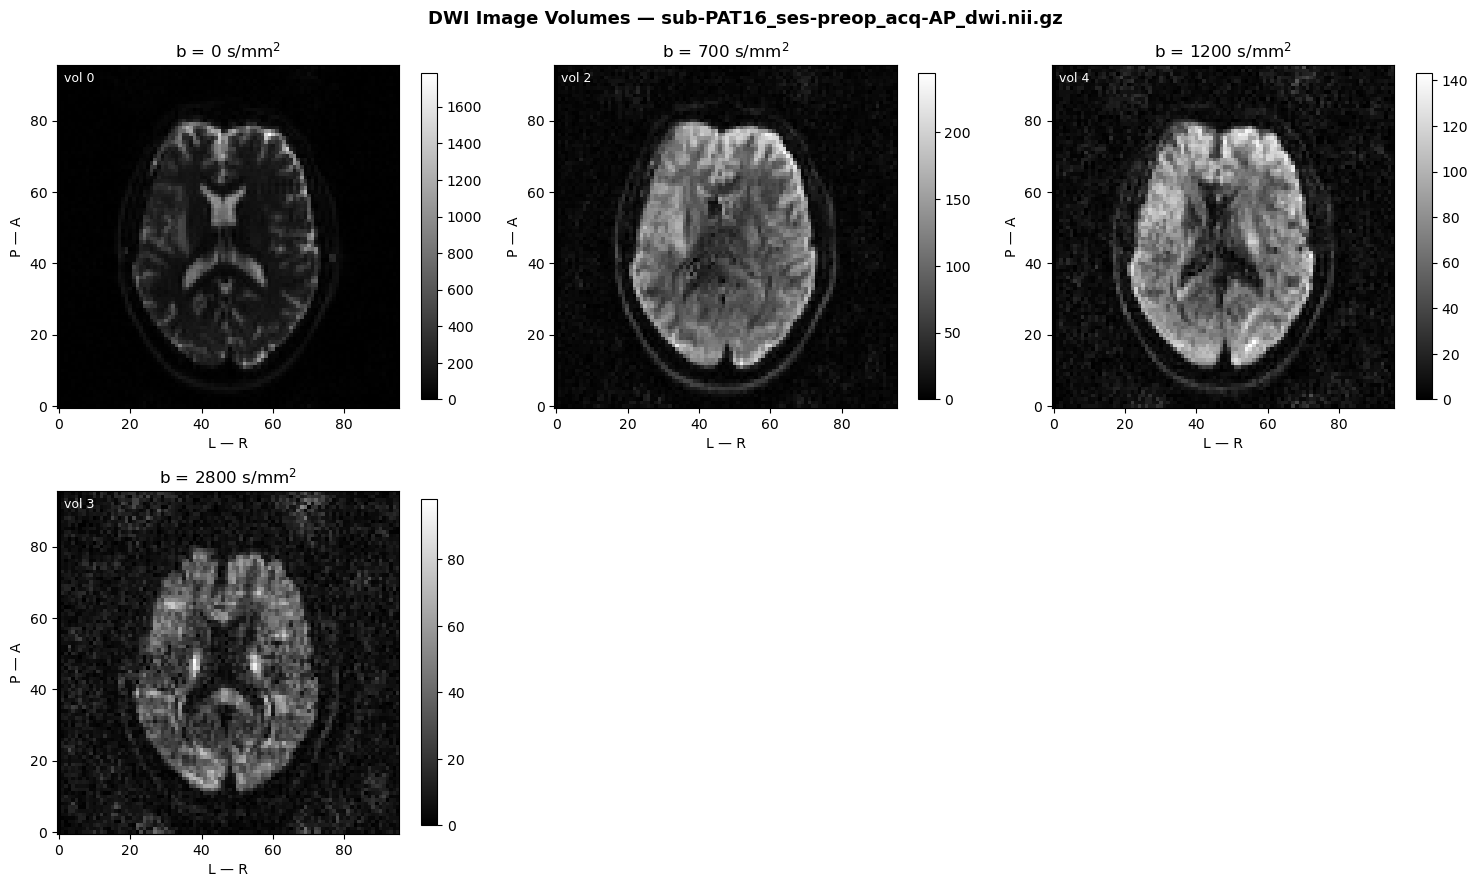

In [31]:
if dwi_data is not None:
    if bvals is not None:
        unique_bvals = np.unique(bvals)
    else:
        unique_bvals = np.array([0, 1])

    n_shells = len(unique_bvals)
    ncols = min(n_shells, 3)
    nrows = int(np.ceil(n_shells / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
    fig.suptitle(f'DWI Image Volumes — {dwi_path.name}',
                 fontsize=13, fontweight='bold')

    if nrows * ncols == 1:
        axes = np.array([axes])
    axes = np.atleast_2d(axes)

    z_idx = dwi_data.shape[2] // 2

    for idx, b_val in enumerate(unique_bvals):
        ax = axes[idx // ncols, idx % ncols]

        vol_idx = int(np.where(bvals == b_val)[0][0]) if bvals is not None else idx
        slice_data = dwi_data[:, :, z_idx, vol_idx]

        # Radiological convention: transpose so A-P runs vertically, anterior at top
        im = ax.imshow(slice_data.T, cmap='gray', origin='lower')
        ax.set_title(f'b = {int(b_val)} s/mm$^2$')
        ax.text(0.02, 0.98, f'vol {vol_idx}', transform=ax.transAxes,
                color='white', verticalalignment='top', fontsize=9)
        ax.set_xlabel('L — R')
        ax.set_ylabel('P — A')
        ax.grid(False)
        plt.colorbar(im, ax=ax, shrink=0.85)

    # Hide unused subplots
    for idx in range(n_shells, nrows * ncols):
        axes[idx // ncols, idx % ncols].set_visible(False)

    plt.tight_layout()
    plt.show()

### 4. B-value Table and Acquisition Summary

In [32]:
if bvals is not None:
    print('\n' + '=' * 60)
    print('DWI ACQUISITION SUMMARY')
    print('=' * 60)
    
    # Create summary table
    unique_b = np.unique(bvals)
    print(f'\nB-value distribution:')
    print(f'{"B-value":12} {"Count":8} {"Percentage":12}')
    print('-' * 35)
    
    for b in unique_b:
        count = (bvals == b).sum()
        pct = 100 * count / len(bvals)
        print(f'{int(b):12} {count:8} {pct:11.1f}%')
    
    print(f'\nTotal volumes: {len(bvals)}')
    
    # DTI acquisition parameters (from JSON if available)
    json_path = str(dwi_path).replace('dwi.nii.gz', 'dwi.json')
    if os.path.exists(json_path):
        import json
        with open(json_path, 'r') as f:
            params = json.load(f)
        
        print(f'\nAcquisition parameters:')
        key_params = ['EchoTime', 'RepetitionTime', 'FlipAngle',
                     'Manufacturer', 'MagneticFieldStrength']
        for key in key_params:
            if key in params:
                print(f'  {key}: {params[key]}')
    
    # Theoretical considerations
    theory_text = '''\nDWI ACQUISITION THEORY:
The diffusion-weighted signal follows:
  S(b) = S0 * exp(-b * ADC)

where:
  S0 = signal without diffusion weighting
  b = b-value (s/mm^2) characterizing the gradient strength
  ADC = apparent diffusion coefficient

MULTI-SHELL DTI:
Using multiple b-values improves tensor estimation.
Typical protocol: b=0 (2-6 volumes), b~700, b~1000, b~2000+ s/mm^2
'''
    print(theory_text)


DWI ACQUISITION SUMMARY

B-value distribution:
B-value      Count    Percentage  
-----------------------------------
           0        6         5.9%
         700       16        15.7%
        1200       30        29.4%
        2800       50        49.0%

Total volumes: 102

Acquisition parameters:
  EchoTime: 0.11
  RepetitionTime: 8.7
  FlipAngle: 90
  Manufacturer: Siemens
  MagneticFieldStrength: 3

DWI ACQUISITION THEORY:
The diffusion-weighted signal follows:
  S(b) = S0 * exp(-b * ADC)

where:
  S0 = signal without diffusion weighting
  b = b-value (s/mm^2) characterizing the gradient strength
  ADC = apparent diffusion coefficient

MULTI-SHELL DTI:
Using multiple b-values improves tensor estimation.
Typical protocol: b=0 (2-6 volumes), b~700, b~1000, b~2000+ s/mm^2



### 5. Compute DTI Metrics (Manual Approach)

In [33]:
# Simplified DTI fitting example
if dwi_data is not None and bvals is not None:
    print('\n' + '=' * 60)
    print('DTI METRIC COMPUTATION')
    print('=' * 60)
    
    # Select the lowest non-zero b-value shell for single-shell ADC demo
    b0_idx = np.where(bvals == 0)[0]
    nonzero_bvals = np.unique(bvals[bvals > 0])
    b_shell = nonzero_bvals[0] if len(nonzero_bvals) > 0 else None
    b_shell_idx = np.where(bvals == b_shell)[0] if b_shell else np.array([])
    
    if len(b_shell_idx) > 0 and len(b0_idx) > 0:
        print(f'\nUsing b = {int(b_shell)} s/mm² shell ({len(b_shell_idx)} volumes, '
              f'{len(b0_idx)} b=0 volumes)')
        print(f'Available shells: {nonzero_bvals.astype(int)}')
        
        # Get a single voxel's signal
        x, y, z = dwi_data.shape[0]//2, dwi_data.shape[1]//2, dwi_data.shape[2]//2
        
        # B0 signal
        S0 = dwi_data[x, y, z, b0_idx].mean()
        
        # DWI signal at chosen shell
        S = dwi_data[x, y, z, b_shell_idx]
        
        # Compute apparent diffusion coefficient (ADC)
        # S = S0 * exp(-b * ADC)
        # ADC = -ln(S/S0) / b
        b_val = b_shell
        ADC = -np.log(np.clip(S / S0, 1e-6, None)) / b_val
        ADC_mean = ADC.mean()
        
        print(f'\nSingle voxel ({x}, {y}, {z}) analysis:')
        print(f'  B0 signal: {S0:.0f}')
        print(f'  DWI signal range: [{S.min():.0f}, {S.max():.0f}]')
        print(f'  ADC values: {ADC}')
        print(f'  Mean ADC: {ADC_mean:.2e} mm^2/s')
        print(f'  Mean ADC: {ADC_mean*1e6:.1f} x10^-6 mm^2/s')
        
        # Create synthetic tensor for demonstration
        print(f'\nSynthetic DTI metric computation (for demonstration):')
        # Eigenvalues (in mm^2/s * 10^-3)
        lambda1 = 2.0e-3  # axial diffusivity
        lambda2 = 0.8e-3  # intermediate
        lambda3 = 0.7e-3  # radial
        
        MD = (lambda1 + lambda2 + lambda3) / 3
        AD = lambda1
        RD = (lambda2 + lambda3) / 2
        
        # Fractional anisotropy
        lambda_mean = MD
        numerator = (lambda1 - lambda_mean)**2 + (lambda2 - lambda_mean)**2 + (lambda3 - lambda_mean)**2
        denominator = lambda1**2 + lambda2**2 + lambda3**2
        FA = np.sqrt(1.5 * numerator / denominator)
        
        print(f'\nEigenvalues (mm^2/s x10^-3):')
        print(f'  λ1 (axial): {lambda1*1e6:.2f}')
        print(f'  λ2: {lambda2*1e6:.2f}')
        print(f'  λ3 (radial): {lambda3*1e6:.2f}')
        
        print(f'\nDTI Metrics:')
        print(f'  FA (Fractional Anisotropy): {FA:.3f}  [range 0-1]')
        print(f'  MD (Mean Diffusivity): {MD*1e6:.2f} x10^-6 mm^2/s')
        print(f'  AD (Axial Diffusivity): {AD*1e6:.2f} x10^-6 mm^2/s')
        print(f'  RD (Radial Diffusivity): {RD*1e6:.2f} x10^-6 mm^2/s')
        
        # Clinical interpretation
        interpretation = '''\nCLINICAL INTERPRETATION:
This voxel shows:''' + (f'\n  - High FA (>0.7): Intact white matter' if FA > 0.7 else f'\n  - Low FA (<0.7): Disrupted white matter') + (f'\n  - Elevated MD: Possible edema' if MD > 1.0e-3 else f'\n  - Normal MD: Healthy tissue')
        print(interpretation)
    else:
        print('Insufficient b-value shell data for DTI fitting')
else:
    print('DWI data not available')


DTI METRIC COMPUTATION

Using b = 700 s/mm² shell (16 volumes, 6 b=0 volumes)
Available shells: [ 700 1200 2800]

Single voxel (48, 48, 30) analysis:
  B0 signal: 150
  DWI signal range: [36, 71]
  ADC values: [0.00159513 0.00140437 0.00171678 0.00153798 0.001127   0.00145632
 0.00184977 0.00106533 0.00151024 0.00145632 0.00162459 0.00110615
 0.00203556 0.00143011 0.00140437 0.00148303]
  Mean ADC: 1.49e-03 mm^2/s
  Mean ADC: 1487.7 x10^-6 mm^2/s

Synthetic DTI metric computation (for demonstration):

Eigenvalues (mm^2/s x10^-3):
  λ1 (axial): 2000.00
  λ2: 800.00
  λ3 (radial): 700.00

DTI Metrics:
  FA (Fractional Anisotropy): 0.553  [range 0-1]
  MD (Mean Diffusivity): 1166.67 x10^-6 mm^2/s
  AD (Axial Diffusivity): 2000.00 x10^-6 mm^2/s
  RD (Radial Diffusivity): 750.00 x10^-6 mm^2/s

CLINICAL INTERPRETATION:
This voxel shows:
  - Low FA (<0.7): Disrupted white matter
  - Elevated MD: Possible edema


### 6. DTI Metrics Maps (DIPY-based)

Computing full-brain DTI metrics with DIPY...
Fitting DTI on ROI of size (48, 48, 20, 102)
DTI fitting complete
FA range: [0.010, 0.983]
MD range: [2.19e-04, 4.08e-03] mm^2/s


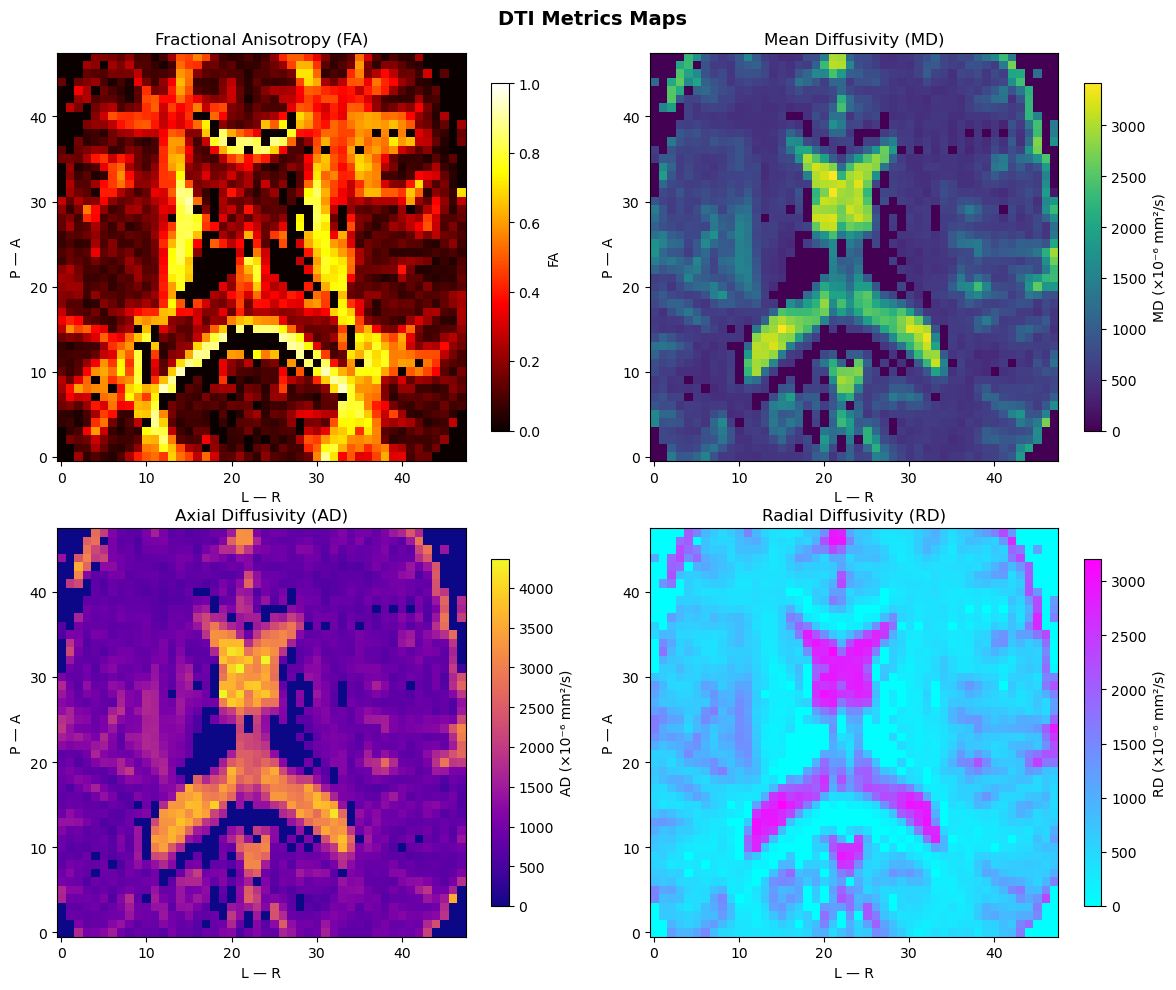

In [34]:
if DIPY_AVAILABLE and dwi_data is not None and bvals is not None and bvecs is not None:
    print('Computing full-brain DTI metrics with DIPY...')
    
    try:
        # Create gradient table
        gtab = gradient_table(bvals, bvecs=bvecs.T)
        
        # Fit DTI on a central ROI for speed
        nx, ny, nz = dwi_data.shape[:3]
        x_start, x_end = nx // 4, 3 * nx // 4
        y_start, y_end = ny // 4, 3 * ny // 4
        z_start, z_end = nz // 3, 2 * nz // 3
        
        roi_data = dwi_data[x_start:x_end, y_start:y_end, z_start:z_end, :]
        print(f'Fitting DTI on ROI of size {roi_data.shape}')
        
        # Fit DTI model
        tenmodel = TensorModel(gtab)
        tenfit = tenmodel.fit(roi_data, mask=roi_data[..., 0] > 100)
        
        # Extract metrics
        FA = tenfit.fa
        MD = tenfit.md
        AD = tenfit.ad
        RD = tenfit.rd
        
        print(f'DTI fitting complete')
        print(f'FA range: [{FA[FA > 0].min():.3f}, {FA.max():.3f}]')
        print(f'MD range: [{MD[MD > 0].min():.2e}, {MD.max():.2e}] mm^2/s')
        
        # Visualize
        fig, axes = plt.subplots(2, 2, figsize=(12, 10))
        fig.suptitle('DTI Metrics Maps', fontsize=14, fontweight='bold')
        
        z_roi = FA.shape[2] // 2
        
        metrics = [
            ('Fractional Anisotropy (FA)', FA, 'hot', dict(vmin=0, vmax=1), 'FA'),
            ('Mean Diffusivity (MD)', MD * 1e6, 'viridis', {}, 'MD (×10⁻⁶ mm²/s)'),
            ('Axial Diffusivity (AD)', AD * 1e6, 'plasma', {}, 'AD (×10⁻⁶ mm²/s)'),
            ('Radial Diffusivity (RD)', RD * 1e6, 'cool', {}, 'RD (×10⁻⁶ mm²/s)'),
        ]
        for idx, (title, data, cmap, kw, cbar_label) in enumerate(metrics):
            ax = axes[idx // 2, idx % 2]
            sl = data[:, :, z_roi]
            im = ax.imshow(sl.T, cmap=cmap, origin='lower', **kw)
            ax.set_title(title)
            ax.set_xlabel('L — R'); ax.set_ylabel('P — A')
            ax.grid(False)
            plt.colorbar(im, ax=ax, label=cbar_label, shrink=0.85)
        
        plt.tight_layout()
        plt.show()
        
    except Exception as e:
        print(f'Error during DTI fitting: {e}')
else:
    if not DIPY_AVAILABLE:
        print('DIPY not available - skipping DTI metric computation')
    else:
        print('Missing DWI data or b-values/b-vectors')

### 7. Fiber Tractography Concepts

In [35]:
tractography_text = '''FIBER TRACTOGRAPHY - CONCEPTS AND MATHEMATICS
=====================================================

GOAL:
Reconstruct white matter fiber pathways from DTI data.

BASIC PRINCIPLE:
Fibers are assumed to follow the principal diffusion direction (PDD),
which is the eigenvector corresponding to λ1 (largest eigenvalue).

STREAMLINE ALGORITHM (Simple Case):
1. Start at seed point r0
2. At position r_n, determine principal diffusion direction: v_n = eigenvector(λ1)
3. Step forward: r_{n+1} = r_n + step_size * v_n
4. Repeat until:
   - FA drops below threshold (leaving white matter)
   - Curvature exceeds maximum angle (anatomically implausible)
   - Exiting brain mask
   - Max steps reached

WHY TRACTOGRAPHY MATTERS FOR GLIOMAS:
1. SURGICAL PLANNING
   - Identify eloquent white matter tracts (motor, language, vision)
   - Plan resection to minimize damage to critical pathways
   - Intraoperative navigation and monitoring

2. TUMOR INFILTRATION ASSESSMENT
   - Examine if tumor displaces or infiltrates tracts
   - Low FA within tumor = infiltration
   - Disrupted tracts = worse prognosis

3. CONNECTIVITY ANALYSIS
   - Quantify connectivity between regions
   - Model information flow in mathematical models
   - Assess functional network integrity

KEY CHALLENGES:
1. FIBER CROSSING
   - Single tensor inadequate where fibers cross
   - Solution: Higher-order models (CSD, HARDI)

2. NOISE AND PARTIAL VOLUME EFFECTS
   - Affects eigenvalue estimates
   - Requires robust fitting strategies

3. ENDPOINT DEFINITION
   - What constitutes a "valid" fiber?
   - Different criteria for different applications

MATHEMATICAL FRAMEWORK:
Local fiber orientation: f(r) = arg max_u u^T D(r) u

Streamline trajectory: dr/dt = f(r(t))

Fiber density along path: integral of local FA values

'''
print(tractography_text)

FIBER TRACTOGRAPHY - CONCEPTS AND MATHEMATICS

GOAL:
Reconstruct white matter fiber pathways from DTI data.

BASIC PRINCIPLE:
Fibers are assumed to follow the principal diffusion direction (PDD),
which is the eigenvector corresponding to λ1 (largest eigenvalue).

STREAMLINE ALGORITHM (Simple Case):
1. Start at seed point r0
2. At position r_n, determine principal diffusion direction: v_n = eigenvector(λ1)
3. Step forward: r_{n+1} = r_n + step_size * v_n
4. Repeat until:
   - FA drops below threshold (leaving white matter)
   - Curvature exceeds maximum angle (anatomically implausible)
   - Exiting brain mask
   - Max steps reached

WHY TRACTOGRAPHY MATTERS FOR GLIOMAS:
1. SURGICAL PLANNING
   - Identify eloquent white matter tracts (motor, language, vision)
   - Plan resection to minimize damage to critical pathways
   - Intraoperative navigation and monitoring

2. TUMOR INFILTRATION ASSESSMENT
   - Examine if tumor displaces or infiltrates tracts
   - Low FA within tumor = infiltratio

### 8. Summary and Clinical Applications

In [36]:
summary = '''DTI AND TRACTOGRAPHY SUMMARY
=============================

KEY TAKEAWAYS:

1. MATHEMATICAL FOUNDATION
   - Diffusion tensor is symmetric 3x3 matrix
   - Eigenvalue decomposition reveals principal directions
   - FA quantifies anisotropy on [0,1] scale
   - MD, AD, RD describe directional diffusion

2. CLINICAL RELEVANCE
   - White matter: High FA (0.7-0.8)
   - Gray matter: Lower FA (0.1-0.3)
   - Tumor: Low FA, high MD (disrupted structure)
   - Edema: Elevated MD

3. DIGITAL TWIN APPLICATIONS
   - DTI metrics inform tumor growth models
   - Anisotropic diffusion equation: du/dt = div(D*grad(u))
   - Tractography defines surgical boundaries
   - Predicts functional deficits from tumor location

4. COMPUTATIONAL CONSIDERATIONS
   - Tensor fitting: Ordinary Least Squares or robust methods
   - Regularization improves estimates in noise
   - Whole-brain computation: minutes on GPU

NEXT STEPS:
- Combine structural (NB02) and diffusion (NB03) data
- Build biomechanical models
- Validate predictions against surgery outcomes
- Extend to advanced models (multi-shell, HARDI)
'''
print(summary)

DTI AND TRACTOGRAPHY SUMMARY

KEY TAKEAWAYS:

1. MATHEMATICAL FOUNDATION
   - Diffusion tensor is symmetric 3x3 matrix
   - Eigenvalue decomposition reveals principal directions
   - FA quantifies anisotropy on [0,1] scale
   - MD, AD, RD describe directional diffusion

2. CLINICAL RELEVANCE
   - White matter: High FA (0.7-0.8)
   - Gray matter: Lower FA (0.1-0.3)
   - Tumor: Low FA, high MD (disrupted structure)
   - Edema: Elevated MD

3. DIGITAL TWIN APPLICATIONS
   - DTI metrics inform tumor growth models
   - Anisotropic diffusion equation: du/dt = div(D*grad(u))
   - Tractography defines surgical boundaries
   - Predicts functional deficits from tumor location

4. COMPUTATIONAL CONSIDERATIONS
   - Tensor fitting: Ordinary Least Squares or robust methods
   - Regularization improves estimates in noise
   - Whole-brain computation: minutes on GPU

NEXT STEPS:
- Combine structural (NB02) and diffusion (NB03) data
- Build biomechanical models
- Validate predictions against surgery ou